# Исправление ошибок наблюдения: остаточная TCN

Сеть предсказывает поправку: `clean_hat = observed − error_hat`. Длина окна сохраняется.
До обучения последний слой выдаёт нулевую поправку, поэтому выход совпадает с входом.
В чистом эталоне остаются случайные экономические изменения.

Параметры: 4 семейства синтетики, 12 траекторий для обучения и выбора настроек, 80 независимых траекторий для итоговой проверки.
Настройки и методы сравнения выбираются на проверочной выборке до генерации тестовых траекторий.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src' / 'tsprep').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'tsprep').is_dir():
    raise RuntimeError('Запустите ноутбук из корня проекта или notebooks')
sys.path.insert(0, str(ROOT / 'src'))
from tsprep.provenance import file_hash, read_json
from tsprep.denoising_experiment import DenoisingProtocol, run_experiment

RESULT = ROOT / 'results' / 'residual_denoising_confirm_20261104'
RUN_NEW_EXPERIMENT = False
# Для повторения задайте новую папку RESULT и включите RUN_NEW_EXPERIMENT.
if RUN_NEW_EXPERIMENT:
    import torch
    from threadpoolctl import threadpool_limits
    with threadpool_limits(limits=2):
        run_experiment(RESULT, DenoisingProtocol(device='cuda' if torch.cuda.is_available() else 'cpu'))
if not (RESULT / 'complete.json').is_file():
    raise RuntimeError('Сначала выполните python -m tsprep.denoising_experiment --out results/residual_denoising_confirm_20261104')
receipt = read_json(RESULT / 'complete.json')
for name, expected in receipt['files'].items():
    if file_hash(RESULT / name) != expected:
        raise ValueError(f'Повреждён артефакт: {name}')
protocol = read_json(RESULT / 'protocol.json')
selection = read_json(RESULT / 'selection.json')
decision = read_json(RESULT / 'decision.json')
assert receipt['status'] == 'complete', 'Smoke не является подтверждающим опытом'
assert selection['frozen_before_confirmation']
print('Проверены контрольные суммы:', len(receipt['files']))
print('Каталог:', RESULT)
print('Время, секунд:', round(receipt['seconds'], 1))


Проверены контрольные суммы: 214
Каталог: e:\SSAU_code\НИР\results\residual_denoising_confirm_20261104
Время, секунд: 376.2


## Проверка обучения и выбор настроек

На 32 отладочных окнах проверяется, способна ли модель подогнать выборку.
Каждый кандидат обучается 120 эпох. Веса выбираются по MAE на проверочной выборке при normal MSE/input ≤ 1.05.
Если подходящих весов нет, используется копирование входа на эпохе 0.


,initial_mse,final_mse,reduction,windows,contaminated_windows,steps,debug_seed,passed,smoke
0,18.791197,4.097534e-07,1.0,32,16,800,9002,True,False


,loss,lr,epoch,mae_ratio,normal_mse_ratio,seconds
0,mae,0.0003,120,0.516691,0.970002,48.360922
1,mae,0.0010,70,0.516709,0.956172,54.703069
2,mse,0.0003,105,0.523676,1.031828,56.090513
3,mse,0.0010,85,0.516260,0.969574,54.039561


Выбрано: mse 0.001
Baseline по validation: global_mad


,model,setting,mae_ratio,normal_mse_ratio
0,pca,8,1.751155,12.695282
1,causal_median,3,1.422119,10.243476
2,causal_hampel,"[9, 5.0]",0.634260,2.345343
3,global_mad,7.0,0.544183,1.000000
4,observed_input,None,1.000000,1.000000
5,train_mean,None,1.971191,16.482700


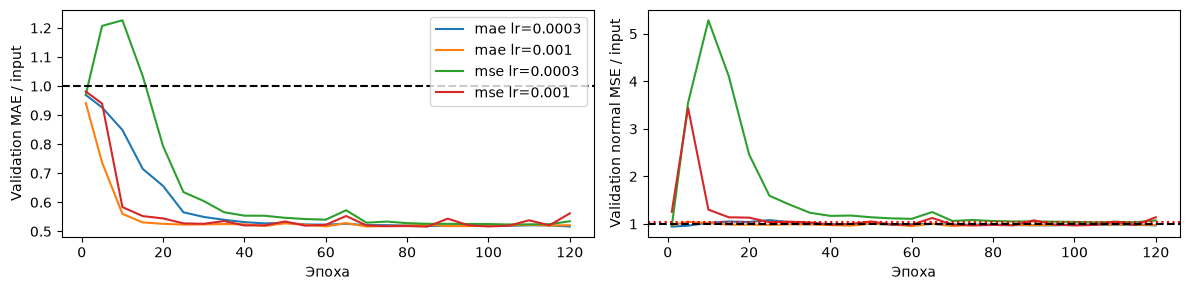

In [2]:
overfit = read_json(RESULT / 'overfit_check.json')
display(pd.DataFrame([{k: v for k, v in overfit.items() if k != 'loss'}]))
candidates = []
for candidate in selection['candidates']:
    candidates.append({'loss': candidate['loss'], 'lr': candidate['lr'], **candidate['best'], 'seconds': candidate['seconds']})
display(pd.DataFrame(candidates))
print('Выбрано:', selection['selected']['loss'], selection['selected']['lr'])
print('Baseline по validation:', selection['baseline']['reference_baseline'])
display(pd.DataFrame(selection['baseline']['choices'].values()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for candidate in selection['candidates']:
    h = pd.DataFrame(candidate['history'])
    label = f"{candidate['loss']} lr={candidate['lr']}"
    axes[0].plot(h.epoch, h.mae_ratio, label=label)
    axes[1].plot(h.epoch, h.normal_mse_ratio, label=label)
for ax, label in zip(axes, ['Validation MAE / input', 'Validation normal MSE / input']):
    ax.axhline(1, color='black', linestyle='--')
    ax.set(xlabel='Эпоха', ylabel=label)
axes[1].axhline(1.05, color='red', linestyle=':')
axes[0].legend()
plt.tight_layout()
plt.show()


## Результаты на новых траекториях

На каждом конце окна учитывается одна оценка. Перекрывающиеся окна не считаются независимыми повторами.
Сначала ошибки усредняются по трём инициализациям внутри траектории, затем по траекториям и семействам.
`ordinary_residual` точно совпадает с входом: для observed→observed копирование уже даёт нулевую ошибку обучения.


,all_mae,all_mse,normal_mae,normal_mse,contaminated_mae,contaminated_mse
model,,,,,,
causal_hampel,0.137050,0.082635,0.123648,0.040606,0.786851,2.110479
causal_median,0.297036,0.195758,0.291094,0.182888,0.586113,0.814739
global_mad,0.117428,0.035891,0.108875,0.018955,0.535388,0.863853
observed_input,0.222260,0.714257,0.108795,0.018600,5.773639,34.757683
ordinary_residual,0.222260,0.714257,0.108795,0.018600,5.773639,34.757683
pca,0.369934,0.230819,0.367605,0.227912,0.484226,0.374784
residual_tcn,0.110923,0.025888,0.104624,0.018594,0.418246,0.380889
train_mean,0.417606,0.295652,0.417527,0.295339,0.422023,0.312320


,all_mae_ratio_to_input,normal_mse_ratio_to_input,contaminated_mae_ratio_to_input
model,,,
causal_hampel,0.619353,2.184963,0.136458
causal_median,1.343648,9.832083,0.101581
global_mad,0.530848,1.019352,0.092871
observed_input,1.000000,1.000000,1.000000
ordinary_residual,1.000000,1.000000,1.000000
pca,1.674416,12.262272,0.083889
residual_tcn,0.501637,1.000154,0.072516
train_mean,1.887644,15.877008,0.073138


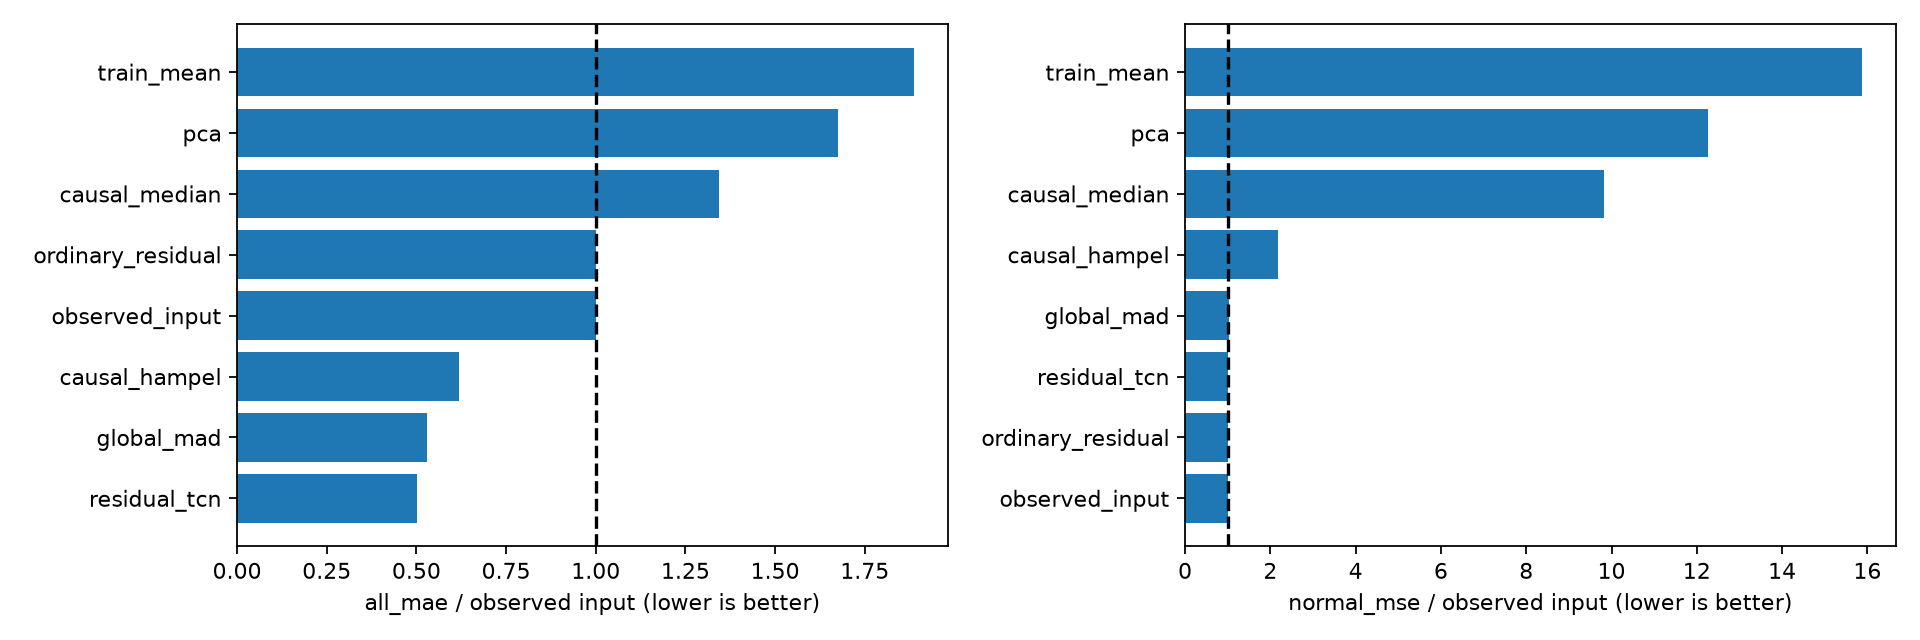

,family,model,all_mae,all_mse,normal_mae,normal_mse,contaminated_mae,contaminated_mse
0,ar1_returns_student_t,causal_hampel,0.136997,0.062695,0.130462,0.050692,0.456245,0.649237
2,ar1_returns_student_t,global_mad,0.115792,0.033183,0.108817,0.019418,0.455624,0.701496
3,ar1_returns_student_t,observed_input,0.222587,0.717640,0.108610,0.018524,5.770806,34.745996
6,ar1_returns_student_t,residual_tcn,0.108148,0.025934,0.102174,0.018782,0.399291,0.374902
8,garch_random_walk_no_seasonality,causal_hampel,0.125783,0.046773,0.118026,0.028865,0.489981,0.887563
10,garch_random_walk_no_seasonality,global_mad,0.114886,0.028322,0.108870,0.018623,0.400357,0.495872
11,garch_random_walk_no_seasonality,observed_input,0.226721,0.739626,0.108870,0.018623,5.761195,34.592196
14,garch_random_walk_no_seasonality,residual_tcn,0.109710,0.023500,0.103885,0.017055,0.383009,0.325319
16,seasonal_period_11,causal_hampel,0.155058,0.160580,0.124355,0.045417,1.615466,5.631563
18,seasonal_period_11,global_mad,0.122756,0.047885,0.108820,0.018653,0.784508,1.426784


model,residual_tcn_all_mae_ratio,global_mad_all_mae_ratio
family,,
ar1_returns_student_t,0.488544,0.523040
garch_random_walk_no_seasonality,0.486090,0.509153
seasonal_period_11,0.501839,0.547349
stochastic_volatility,0.530075,0.543849


model,residual_tcn_normal_mse_ratio,global_mad_normal_mse_ratio
family,,
ar1_returns_student_t,1.014088,1.048520
garch_random_walk_no_seasonality,0.915846,1.000000
seasonal_period_11,0.949514,1.000000
stochastic_volatility,1.121169,1.028888


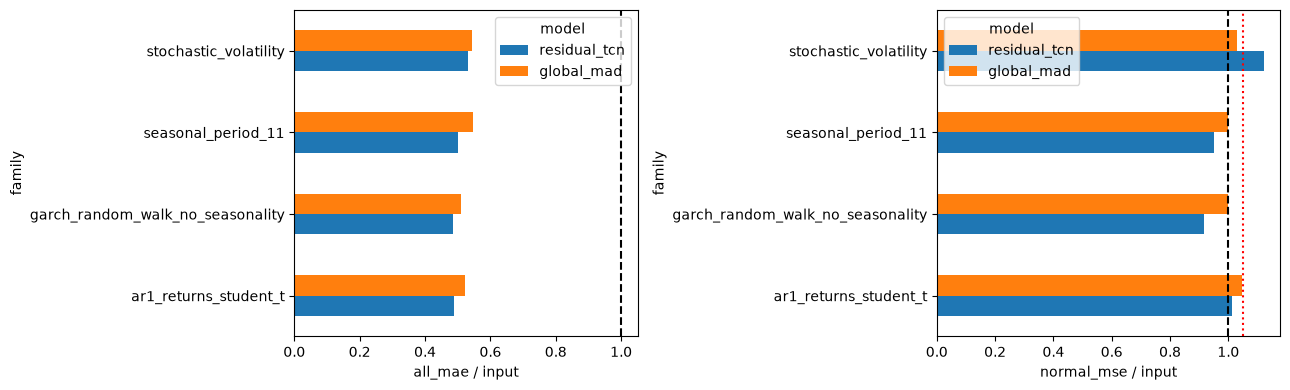

In [3]:
summary = pd.read_csv(RESULT / 'summary.csv').set_index('model')
display(summary)
endpoints = pd.read_csv(RESULT / 'endpoint_metrics.csv')
trajectory_means = endpoints.groupby(['family', 'data_seed', 'model'])[['all_mae', 'normal_mse', 'contaminated_mae']].mean()
ratio = pd.DataFrame({metric: trajectory_means[metric].unstack('model').pipe(lambda a: a.div(a['observed_input'], axis=0)).mean() for metric in trajectory_means.columns})
display(ratio.rename(columns=lambda x: x + '_ratio_to_input'))
display(Image(filename=str(RESULT / 'quality_ratios.png')))
by_family = pd.read_csv(RESULT / 'summary_by_family.csv')
display(by_family[by_family.model.isin(['observed_input', 'residual_tcn', 'global_mad', 'causal_hampel'])])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ['all_mae', 'normal_mse']):
    a = trajectory_means[metric].unstack('model')
    family_ratios = a.div(a['observed_input'], axis=0).groupby('family').mean()[['residual_tcn', 'global_mad']]
    display(family_ratios.rename(columns=lambda name: name + '_' + metric + '_ratio'))
    family_ratios.plot.barh(ax=ax)
    ax.axvline(1, color='black', linestyle='--')
    if metric == 'normal_mse':
        ax.axvline(1.05, color='red', linestyle=':', label='guard 1.05')
    ax.set_xlabel(metric + ' / input')
plt.tight_layout()
plt.show()


## Неопределённость и критерий успеха

Бутстреп повторно выбирает независимые траектории внутри каждого семейства; прогнозы не объединяются в ансамбль.
Для выполнения критерия обе верхние односторонние границы 97.5% должны удовлетворять условиям:
MAE/input < 1 и normal MSE/input ≤ 1.05. Интервалы зависят от выборки для обучения и выбора настроек и от обученных моделей.
Сравнения с остальными методами носят описательный характер. Средний результат не гарантирует улучшения в каждом семействе.


In [4]:
intervals = []
for model, item in decision['methods'].items():
    for reference, comparison in item['comparisons'].items():
        for metric, interval in comparison.items():
            intervals.append({'model': model, 'reference': reference, 'metric': metric, **interval})
display(pd.DataFrame(intervals))
print('Совместный критерий для residual TCN:', decision['methods']['residual_tcn']['joint_success'])


,model,reference,metric,mean,lower,upper,unit,families,trajectories_per_family,repeats,conditional_on
0,observed_input,observed_input,all_mae,1.000000,1.000000,1.000000,independent_trajectory,4,20,5000,development data and fixed initialization seeds
1,observed_input,observed_input,normal_mse,1.000000,1.000000,1.000000,independent_trajectory,4,20,5000,development data and fixed initialization seeds
2,observed_input,global_mad,all_mae,1.892819,1.867390,1.919024,independent_trajectory,4,20,5000,development data and fixed initialization seeds
3,observed_input,global_mad,normal_mse,0.984009,0.973130,0.993396,independent_trajectory,4,20,5000,development data and fixed initialization seeds
4,train_mean,observed_input,all_mae,1.887644,1.853799,1.921157,independent_trajectory,4,20,5000,development data and fixed initialization seeds
5,train_mean,observed_input,normal_mse,15.877008,15.678848,16.071810,independent_trajectory,4,20,5000,development data and fixed initialization seeds
6,train_mean,global_mad,all_mae,3.537347,3.510552,3.564526,independent_trajectory,4,20,5000,development data and fixed initialization seeds
7,train_mean,global_mad,normal_mse,15.664120,15.441744,15.886981,independent_trajectory,4,20,5000,development data and fixed initialization seeds
8,pca,observed_input,all_mae,1.674416,1.647510,1.700835,independent_trajectory,4,20,5000,development data and fixed initialization seeds
9,pca,observed_input,normal_mse,12.262272,12.088552,12.437452,independent_trajectory,4,20,5000,development data and fixed initialization seeds


Совместный критерий для residual TCN: True


## Повреждение сигнала без ошибок наблюдения

Те же чистые экономические траектории подаются на вход без добавленного шума и импульсов.
Ошибка входа в этом контроле равна нулю; здесь показываются абсолютные MAE/MSE, без отношений к нулю.


,mae,mse
method,,
causal_hampel,0.019674,0.025773
causal_median,0.265361,0.182009
global_mad,0.000101,0.000552
observed_input,0.000000,0.000000
pca,0.343469,0.200746
residual_tcn,0.036409,0.003858
train_mean,0.417606,0.295652


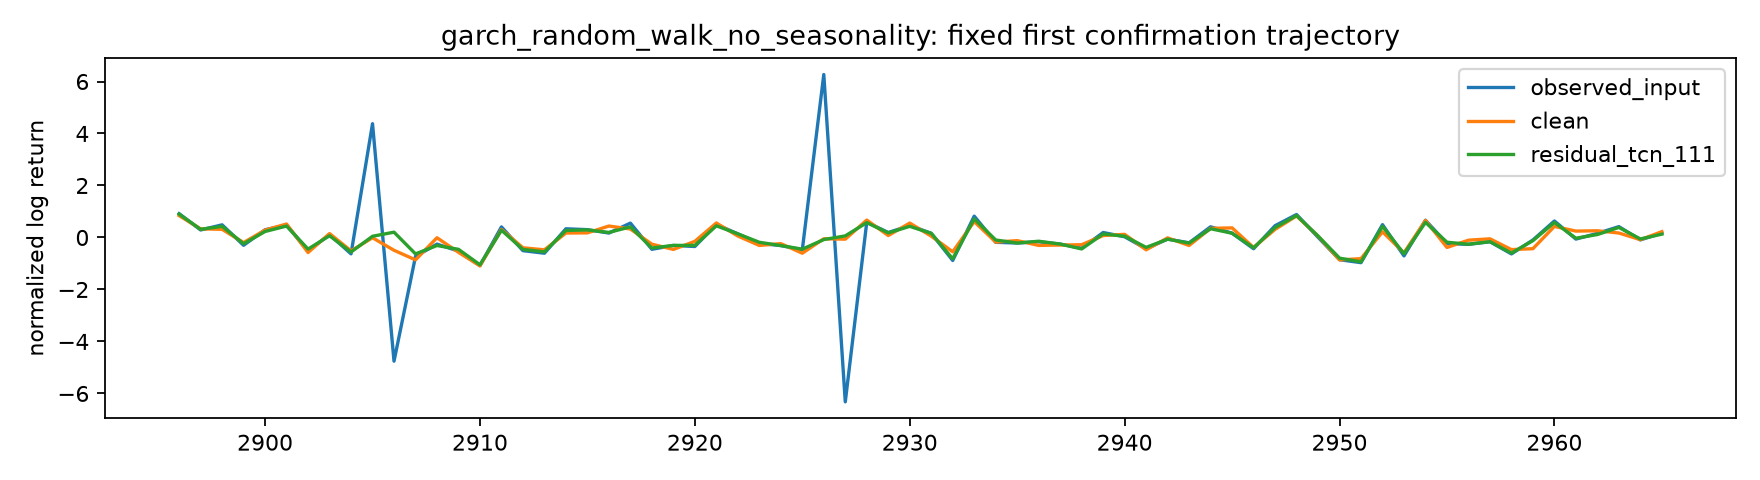

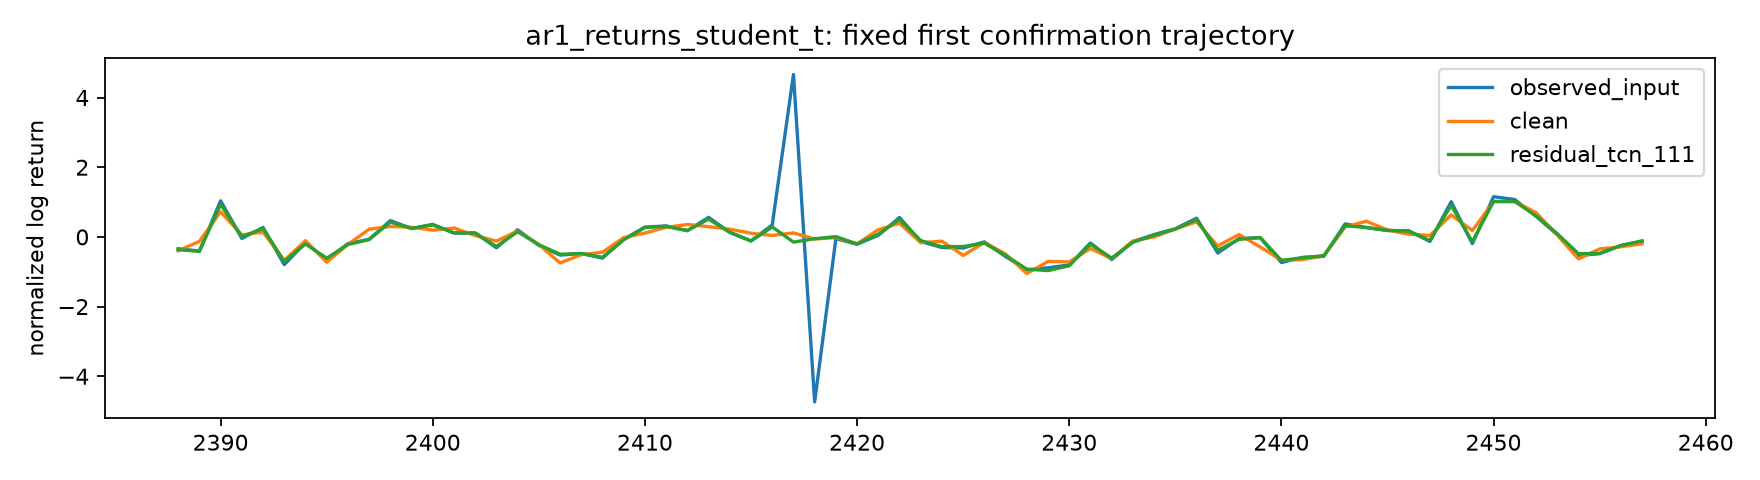

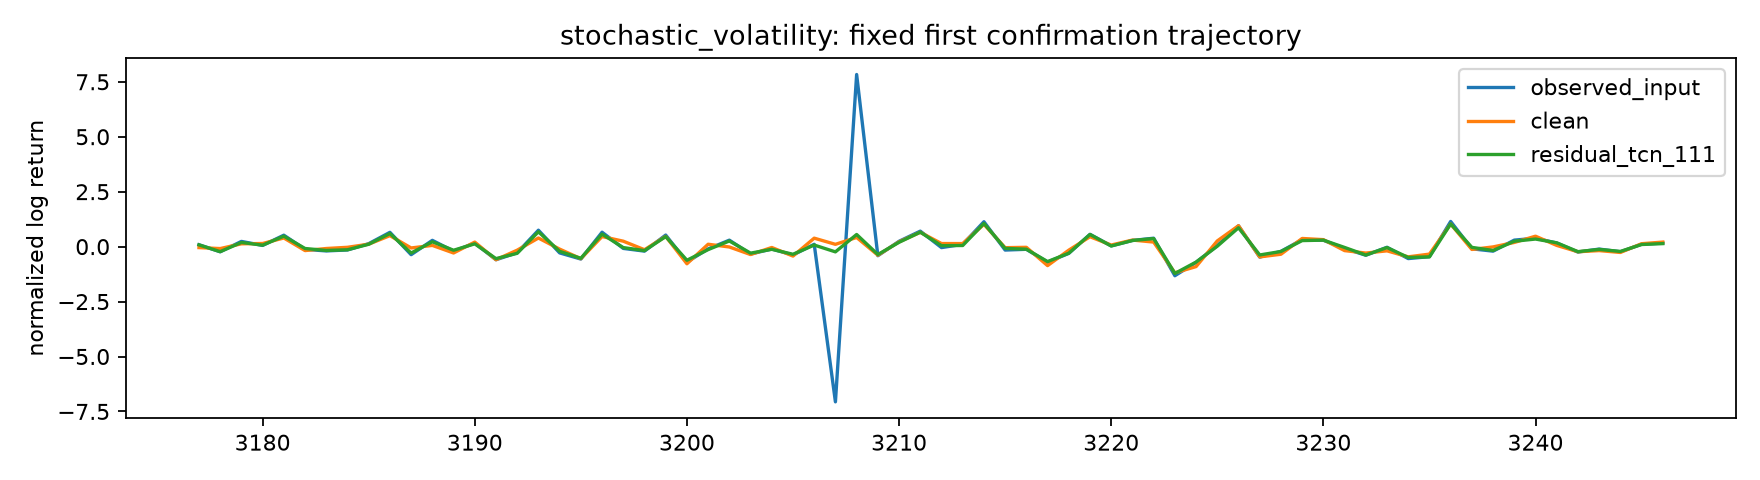

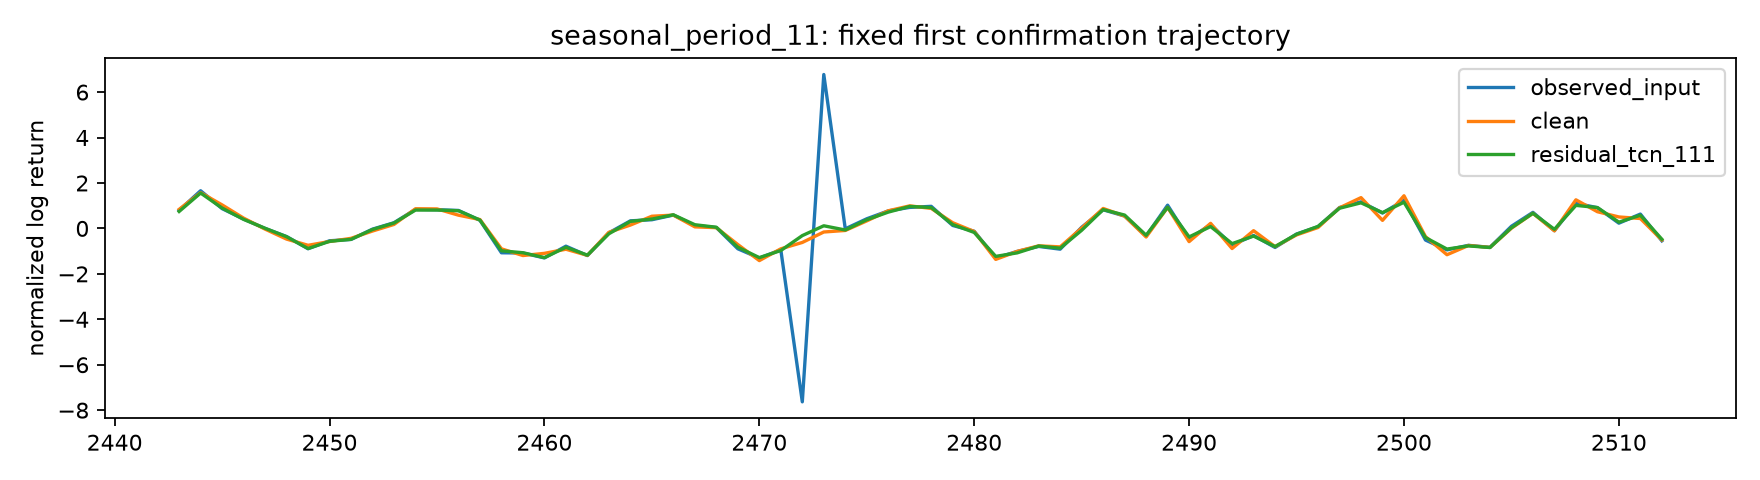

In [5]:
pristine = pd.read_csv(RESULT / 'pristine_metrics.csv')
pristine['method'] = pristine.model.str.replace(r'residual_tcn_\d+$', 'residual_tcn', regex=True)
display(pristine.groupby(['family', 'data_seed', 'method'])[['mae', 'mse']].mean().groupby('method').mean())
for family in protocol['families']:
    display(Image(filename=str(RESULT / f'example_{family}.png')))


## Отдельная проверка прогноза

Ridge прогнозирует чистую логарифмическую доходность ровно через 7 шагов.
Используются последние 16 значений окна 48: для каждого доступно полное поле восприятия TCN по прошлым наблюдениям.
Коэффициент Ridge выбирается на проверочной выборке, затем фиксируется. Снижение MAE удаления шума не гарантирует улучшения прогноза.


In [6]:
forecast = pd.read_csv(RESULT / 'forecast_summary.csv').set_index('model')
display(forecast)
print('Цель:', read_json(RESULT / 'forecast_probes.json')['target'])


,mae,mse
model,,
causal_hampel,0.376282,0.240300
causal_median,0.376138,0.239784
forecast_mean,0.417549,0.295554
forecast_median,0.417546,0.295550
global_mad,0.374902,0.238346
observed_input,0.381697,0.245793
pca,0.366090,0.227821
residual_tcn,0.373135,0.236292
train_mean,0.417549,0.295554


Цель: clean_log_return_at_endpoint_plus_7


## Ограничения

Проверяется перенос на новые траектории тех же четырёх генераторов. Работа на неизвестных семействах и реальных рынках здесь не проверяется.
Ограничение normal MSE допускает небольшой ущерб; проверка чистого входа позволяет его увидеть.
Настоящий рыночный скачок без дополнительных данных может быть неотличим от ошибки наблюдения.
Для повторного подбора настроек нельзя использовать итоговые тестовые траектории. После изменения метода нужна новая проверка.
